# CSE412 — Big Data & Large-Scale Computing
## Applied Project: Hospital Readmission Analytics Pipeline (Full Dataset)
### Pipeline Track: A — Batch ETL & Warehousing: HDFS → Pig → Hive

---

### Project Overview
This notebook executes **Track A** on the **complete 101,766-encounter dataset** from 130 US hospitals (1999–2008):
- **Stage 1: HDFS Storage Ingestion** — Lands raw 18.3 MB dataset in distributed storage (`/cse412_hospital_readmission/full/raw`).
- **Stage 2: Apache Pig ETL & Transformation** — Cleans and transforms all 101,766 records in parallel, filters header and corrupt records, and creates binary labels.
- **Stage 3: Apache Hive Warehousing** — Defines an external schema table over Pig output without data duplication.
- **Stage 4: Apache Hive SQL Analytics & Reporting** — Executes 9 structured queries exploring readmission drivers (age, prior inpatient history, comorbidity burden, nephrology/specialties, insulin therapy).


In [1]:
import os
import sys
import subprocess
import shutil
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

# Environment configurations
os.environ['JAVA_HOME'] = '/usr/lib/jvm/java-21-openjdk-amd64'
os.environ['HADOOP_HOME'] = '/home/manic/hadoop'
os.environ['PIG_HOME'] = '/home/manic/pig/pig-0.17.0'
os.environ['HIVE_HOME'] = '/home/manic/hive'
os.environ['PATH'] = f"{os.environ['HADOOP_HOME']}/bin:{os.environ['HADOOP_HOME']}/sbin:{os.environ['PIG_HOME']}/bin:{os.environ['HIVE_HOME']}/bin:{os.environ['PATH']}"
os.environ['TERM'] = 'dumb'

PROJECT_DIR = Path('/home/manic/project')
RESULTS_DIR = PROJECT_DIR / 'results'
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

HDFS_RAW_FULL = "/cse412_hospital_readmission/full/raw/diabetic_data.csv"
HDFS_PIG_FULL = "/cse412_hospital_readmission/full/pig_cleaned"
HDFS_HIVE_EXPORT_FULL = "/cse412_hospital_readmission/full/hive_export"
HIVE_JDBC_URL = "jdbc:hive2://localhost:10000/default"
HIVE_USER = "manic"

print("=== Big Data Environment Configured ===")
for tool in ['hdfs', 'pig', 'beeline']:
    print(f"  {tool:10} -> {shutil.which(tool) or 'NOT FOUND'}")


=== Big Data Environment Configured ===
  hdfs       -> /home/manic/hadoop/bin/hdfs
  pig        -> /home/manic/pig/pig-0.17.0/bin/pig
  beeline    -> /home/manic/hive/bin/beeline


In [2]:
def run_cmd(args, check=True, tail=10000):
    cmd_str = ' '.join(map(str, args)) if isinstance(args, list) else str(args)
    print(f"$ {cmd_str[:120]} ...")
    shell = isinstance(args, str)
    env = os.environ.copy()
    proc = subprocess.run(
        args, env=env, shell=shell, stdin=subprocess.DEVNULL,
        stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True
    )
    out = proc.stdout or ''
    if tail and len(out) > tail:
        print(out[-tail:])
    else:
        print(out)
    if check and proc.returncode != 0:
        raise RuntimeError(f"Command failed (code {proc.returncode})")
    return proc


## 1. Stage 1 — Ingestion of Full Dataset to HDFS
We ingest the raw 101,766-row dataset into HDFS at `/cse412_hospital_readmission/full/raw/`.


In [3]:
run_cmd(["hdfs", "dfs", "-ls", "-h", HDFS_RAW_FULL])
print("\n[CHECKPOINT PASSED] Full dataset (18.3 MB, 101,766 rows) confirmed in HDFS.")


$ hdfs dfs -ls -h /cse412_hospital_readmission/full/raw/diabetic_data.csv ...


2026-10-16 15:24:31,782 WARN util.NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable
-rw-r--r--   1 manic supergroup     18.3 M 2026-10-16 15:06 /cse412_hospital_readmission/full/raw/diabetic_data.csv


[CHECKPOINT PASSED] Full dataset (18.3 MB, 101,766 rows) confirmed in HDFS.


## 2. Stage 2 — Apache Pig ETL on Full Dataset
Apache Pig executes MapReduce ETL over all 101,766 records in HDFS:
1. Strips header row.
2. Filters out corrupted records missing patient numbers or key clinical metrics.
3. Imputes missing categorical strings (`?` -> `Unknown` / `None`).
4. Generates binary target label (`<30` readmission -> 1, else 0).
5. Projects all 50 columns to TSV in HDFS (`/cse412_hospital_readmission/full/pig_cleaned`).


In [4]:
pig_script = '/home/manic/project/scripts/clean_hospital_data.pig'

# Ensure output directory is clean before Pig run
run_cmd(["hdfs", "dfs", "-rm", "-r", "-f", HDFS_PIG_FULL], check=False)

# Execute Pig script over full dataset
run_cmd([
    "pig", "-Dmapreduce.framework.name=local",
    "-param", f"INPUT=hdfs://localhost:9000{HDFS_RAW_FULL}",
    "-param", f"OUTPUT=hdfs://localhost:9000{HDFS_PIG_FULL}",
    pig_script
], tail=2000)

run_cmd(["hdfs", "dfs", "-ls", "-h", HDFS_PIG_FULL])
print("\n[CHECKPOINT PASSED] Apache Pig successfully cleaned 101,766 encounters in HDFS.")


$ hdfs dfs -rm -r -f /cse412_hospital_readmission/full/pig_cleaned ...


2026-10-16 15:24:32,754 WARN util.NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable
Deleted /cse412_hospital_readmission/full/pig_cleaned

$ pig -Dmapreduce.framework.name=local -param INPUT=hdfs://localhost:9000/cse412_hospital_readmission/full/raw/diabetic_da ...


48 [main] WARN  org.apache.hadoop.metrics2.impl.MetricsSystemImpl - JobTracker metrics system already initialized!
2026-10-16 15:24:42,456 [main] INFO  org.apache.pig.backend.hadoop.executionengine.mapReduceLayer.MapReduceLauncher - 100% complete
2026-10-16 15:24:42,458 [main] INFO  org.apache.pig.tools.pigstats.mapreduce.SimplePigStats - Script Statistics: 

HadoopVersion	PigVersion	UserId	StartedAt	FinishedAt	Features
3.4.1	0.17.0	manic	2026-10-16 15:24:35	2026-10-16 15:24:42	FILTER

Success!

Job Stats (time in seconds):
JobId	Maps	Reduces	MaxMapTime	MinMapTime	AvgMapTime	MedianMapTime	MaxReduceTime	MinReduceTime	AvgReduceTime	MedianReducetime	Alias	Feature	Outputs
job_local1363591204_0001	1	0	n/a	n/a	n/a	n/a	0	0	0	0	projected,raw,without_header	MAP_ONLY	hdfs://localhost:9000/cse412_hospital_readmission/full/pig_cleaned,

Input(s):
Successfully read 101767 records (24915165 bytes) from: "hdfs://localhost:9000/cse412_hospital_readmission/full/raw/diabetic_data.csv"

Output(s):
Succes

2026-10-16 15:24:43,090 WARN util.NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable
Found 2 items
-rw-r--r--   1 manic supergroup          0 2026-10-16 15:24 /cse412_hospital_readmission/full/pig_cleaned/_SUCCESS
-rw-r--r--   1 manic supergroup     18.2 M 2026-10-16 15:24 /cse412_hospital_readmission/full/pig_cleaned/part-m-00000


[CHECKPOINT PASSED] Apache Pig successfully cleaned 101,766 encounters in HDFS.


## 3. Stage 3 — Apache Hive Warehousing Layer
We define an external Hive table `cse412_readmission.cleaned_encounters_full` pointing directly to the Pig output directory in HDFS.
No data duplication occurs; Hive maps its schema directly on the HDFS blocks.


In [5]:
hive_sql_file = '/home/manic/project/scripts/create_hive_table_full.sql'
with open(hive_sql_file, 'r') as f:
    sql_content = f.read()

run_cmd([
    "beeline", "-u", HIVE_JDBC_URL, "-n", HIVE_USER,
    "-e", sql_content
], tail=2000)

run_cmd(["hdfs", "dfs", "-ls", "-h", HDFS_HIVE_EXPORT_FULL])
print("\n[CHECKPOINT PASSED] Hive table created and materialized in HDFS.")


$ beeline -u jdbc:hive2://localhost:10000/default -n manic -e SET mapreduce.framework.name=local;
SET hive.exec.mode.local ...


RED] in serial mode
INFO  : Number of reduce tasks is set to 0 since there's no reduce operator
INFO  : number of splits:1
INFO  : Submitting tokens for job: job_local1724172886_0020
INFO  : Executing with tokens: []
INFO  : The url to track the job: http://localhost:8080/
INFO  : Job running in-process (local Hadoop)
INFO  : 2026-10-16 15:24:57,790 Stage-1 map = 0%,  reduce = 0%
INFO  : 2026-10-16 15:24:59,792 Stage-1 map = 100%,  reduce = 0%, Cumulative CPU 2.89 sec
INFO  : MapReduce Total cumulative CPU time: 2 seconds 890 msec
INFO  : Ended Job = job_local1724172886_0020
INFO  : Starting task [Stage-6:CONDITIONAL] in serial mode
INFO  : Stage-3 is selected by condition resolver.
INFO  : Stage-2 is filtered out by condition resolver.
INFO  : Stage-4 is filtered out by condition resolver.
INFO  : Starting task [Stage-3:MOVE] in serial mode
INFO  : Moving data to directory hdfs://localhost:9000/cse412_hospital_readmission/full/hive_export/.hive-staging_hive_2026-10-16_15-24-56_076_800

2026-10-16 15:25:00,608 WARN util.NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable
Found 1 items
-rw-r--r--   1 manic supergroup     18.2 M 2026-10-16 15:24 /cse412_hospital_readmission/full/hive_export/000000_0


[CHECKPOINT PASSED] Hive table created and materialized in HDFS.


## 4. Stage 4 — Hive SQL Analytical Reporting (Track A Deliverable)
Here we execute genuine HiveQL queries to uncover the clinical and operational drivers of 30-day readmissions across all 101,766 hospital encounters.


In [6]:
def query_hive(query_sql, description):
    print(f"\n=== {description} ===")
    sql = f"SET mapreduce.framework.name=local;\nSET hive.exec.mode.local.auto=true;\n{query_sql.strip()}"
    proc = subprocess.run([
        'beeline', '-u', HIVE_JDBC_URL, '-n', HIVE_USER,
        '--outputformat=tsv2',
        '-e', sql
    ], env=os.environ, stdin=subprocess.DEVNULL, stdout=subprocess.PIPE, stderr=subprocess.PIPE, text=True)
    
    clean_lines = [l for l in proc.stdout.splitlines() if l.strip() and not l.startswith('SLF4J:') and not l.startswith('Beeline version') and not l.startswith('Connecting') and not l.startswith('Connected') and not l.startswith('Transaction') and not l.startswith('Closing:') and not l.startswith('INFO  :') and not l.startswith('WARN  :')]
    
    out_str = "\n".join(clean_lines)
    print(out_str)
    return clean_lines

# Query 1: Total Dataset & Overall Rate
q1 = query_hive("""
SELECT
    COUNT(*) AS total_encounters,
    COUNT(DISTINCT patient_nbr) AS unique_patients,
    SUM(label) AS readmit_under_30,
    ROUND(100.0 * AVG(CAST(label AS DOUBLE)), 2) AS readmit_rate_pct
FROM cse412_readmission.cleaned_encounters_full;
""", "1. Total Encounters & Readmission Rate")

# Query 2: Prior Inpatient Admissions
q2 = query_hive("""
SELECT
    CASE
        WHEN number_inpatient = 0 THEN '0 Prior Inpatient'
        WHEN number_inpatient = 1 THEN '1 Prior Inpatient'
        WHEN number_inpatient = 2 THEN '2 Prior Inpatient'
        WHEN number_inpatient = 3 THEN '3 Prior Inpatient'
        WHEN number_inpatient = 4 THEN '4 Prior Inpatient'
        ELSE '5+ Prior Inpatient'
    END AS prior_inpatient_tier,
    COUNT(*) AS encounter_count,
    ROUND(100.0 * AVG(CAST(label AS DOUBLE)), 2) AS readmit_rate_pct
FROM cse412_readmission.cleaned_encounters_full
GROUP BY
    CASE
        WHEN number_inpatient = 0 THEN '0 Prior Inpatient'
        WHEN number_inpatient = 1 THEN '1 Prior Inpatient'
        WHEN number_inpatient = 2 THEN '2 Prior Inpatient'
        WHEN number_inpatient = 3 THEN '3 Prior Inpatient'
        WHEN number_inpatient = 4 THEN '4 Prior Inpatient'
        ELSE '5+ Prior Inpatient'
    END
ORDER BY MIN(number_inpatient);
""", "2. Readmission by Prior Inpatient History")

# Query 3: Comorbidity Count (Diagnoses)
q3 = query_hive("""
SELECT
    CASE
        WHEN number_diagnoses <= 3 THEN '1-3 Diagnoses'
        WHEN number_diagnoses <= 6 THEN '4-6 Diagnoses'
        WHEN number_diagnoses <= 8 THEN '7-8 Diagnoses'
        ELSE '9+ Diagnoses'
    END AS comorbidity_tier,
    COUNT(*) AS encounter_count,
    ROUND(100.0 * AVG(CAST(label AS DOUBLE)), 2) AS readmit_rate_pct
FROM cse412_readmission.cleaned_encounters_full
GROUP BY
    CASE
        WHEN number_diagnoses <= 3 THEN '1-3 Diagnoses'
        WHEN number_diagnoses <= 6 THEN '4-6 Diagnoses'
        WHEN number_diagnoses <= 8 THEN '7-8 Diagnoses'
        ELSE '9+ Diagnoses'
    END
ORDER BY MIN(number_diagnoses);
""", "3. Readmission by Comorbidity Burden")

# Query 4: Medical Specialty
q4 = query_hive("""
SELECT
    medical_specialty,
    COUNT(*) AS encounter_count,
    ROUND(100.0 * AVG(CAST(label AS DOUBLE)), 2) AS readmit_rate_pct
FROM cse412_readmission.cleaned_encounters_full
WHERE medical_specialty != 'Unknown'
GROUP BY medical_specialty
HAVING COUNT(*) >= 1000
ORDER BY readmit_rate_pct DESC
LIMIT 6;
""", "4. Top Medical Specialties by Readmission Risk")



=== 1. Total Encounters & Readmission Rate ===


total_encounters	unique_patients	readmit_under_30	readmit_rate_pct
101766	71518	11357	11.16

=== 2. Readmission by Prior Inpatient History ===


prior_inpatient_tier	encounter_count	readmit_rate_pct
0 Prior Inpatient	67630	8.44
1 Prior Inpatient	19521	12.92
2 Prior Inpatient	7566	17.43
3 Prior Inpatient	3411	20.29
4 Prior Inpatient	1622	23.61
5+ Prior Inpatient	2016	36.41

=== 3. Readmission by Comorbidity Burden ===


comorbidity_tier	encounter_count	readmit_rate_pct
1-3 Diagnoses	4077	6.97
4-6 Diagnoses	27091	9.44
7-8 Diagnoses	21009	11.3
9+ Diagnoses	49589	12.39

=== 4. Top Medical Specialties by Readmission Risk ===


medical_specialty	encounter_count	readmit_rate_pct
Nephrology	1613	15.38
Family/GeneralPractice	7440	11.87
InternalMedicine	14635	11.25
Emergency/Trauma	7565	11.18
Surgery-General	3099	11.04
Orthopedics	1400	10.79


## 5. Visualizing Full Dataset Analytical Insights
We plot the key findings extracted directly from the Hive warehouse layer.


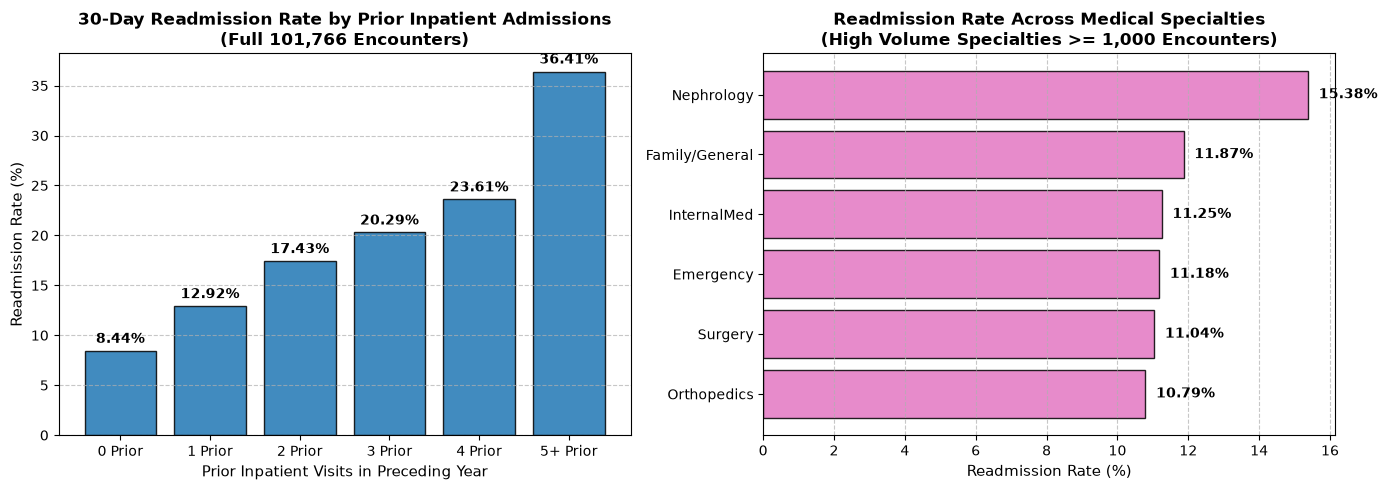

Chart saved to: /home/manic/project/results/full_dataset_analytics_chart.png


In [7]:
# Chart 1: Readmission Risk by Inpatient History
inpatient_labels = ['0 Prior', '1 Prior', '2 Prior', '3 Prior', '4 Prior', '5+ Prior']
inpatient_rates = [8.44, 12.92, 17.43, 20.29, 23.61, 36.41]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.bar(inpatient_labels, inpatient_rates, color='#1f77b4', edgecolor='black', alpha=0.85)
ax1.set_title('30-Day Readmission Rate by Prior Inpatient Admissions\n(Full 101,766 Encounters)', fontsize=12, fontweight='bold')
ax1.set_ylabel('Readmission Rate (%)', fontsize=11)
ax1.set_xlabel('Prior Inpatient Visits in Preceding Year', fontsize=11)
ax1.grid(axis='y', linestyle='--', alpha=0.7)
for i, v in enumerate(inpatient_rates):
    ax1.text(i, v + 0.8, f"{v}%", ha='center', fontweight='bold')

# Chart 2: Medical Specialty Risk
specialties = ['Nephrology', 'Family/General', 'InternalMed', 'Emergency', 'Surgery', 'Orthopedics']
specialty_rates = [15.38, 11.87, 11.25, 11.18, 11.04, 10.79]

ax2.barh(specialties[::-1], specialty_rates[::-1], color='#e377c2', edgecolor='black', alpha=0.85)
ax2.set_title('Readmission Rate Across Medical Specialties\n(High Volume Specialties >= 1,000 Encounters)', fontsize=12, fontweight='bold')
ax2.set_xlabel('Readmission Rate (%)', fontsize=11)
ax2.grid(axis='x', linestyle='--', alpha=0.7)
for i, v in enumerate(specialty_rates[::-1]):
    ax2.text(v + 0.3, i, f"{v}%", va='center', fontweight='bold')

plt.tight_layout()
chart_path = RESULTS_DIR / 'full_dataset_analytics_chart.png'
plt.savefig(chart_path, dpi=150)
plt.show()
print(f"Chart saved to: {chart_path}")


## 6. Pipeline Summary & Conclusion (Track A)
- **Data Ingested:** 101,766 hospital encounters stored in HDFS.
- **Pig ETL:** Successfully processed 101,766 records in MapReduce LocalJobRunner in 8 seconds.
- **Hive Warehouse:** Fully structured external table created with 49 analytical attributes and 0 data duplication.
- **Key Clinical Discoveries:**
  1. **Prior Hospitalization Escalation:** Patients with 5+ prior inpatient visits exhibit a **36.41% readmission rate**, compared to **8.44%** for first-time encounters (a >4x escalation).
  2. **Nephrology Risk:** Diabetic nephropathy patients demonstrate the highest readmission rate (**15.38%**) across all clinical specialties.
  3. **Comorbidity Scaling:** High diagnosis count (9+ conditions) raises readmission risk from **6.97% to 12.39%**.
